# Clase 10 — Analizando el catálogo de Netflix

En este ejercicio asumirás el rol de un **Data Analyst** dentro de Netflix. El equipo de negocio quiere entender mejor cómo está distribuido el catálogo de la plataforma para tomar decisiones sobre futuras inversiones en contenido.

Para ello deberás utilizar las herramientas aprendidas en esta clase:

- `groupby()`
- funciones de agregación
- `agg()`
- `pivot_table()`
- `unstack()`
- gráficos con Pandas y Matplotlib

> No utilices bucles (`for`) para resolver los ejercicios.


## Parte 1: Exploración del dataset

Antes de comenzar el análisis responde:

1. Carga el dataset.
2. Muestra las primeras filas.
3. ¿Cuántas filas y columnas posee?
4. ¿Qué tipo de dato tiene cada columna?
5. ¿Existen valores nulos?
6. ¿Qué columnas presentan mayor cantidad de valores faltantes?

In [ ]:
# tú código acá
import sqlite3
import pandas as pd

conexion = sqlite3.connect("netflix_data.csv")

df=pd.read_csv("netflix_data.csv")
#Muestra de las primeras filas y columnas
df.head()
#Muestra cantidad de filas y columnas (num)
print(df.shape)

#Tipo  de dato de cada columna (nulos)
df.info()

#5)Si, existen valores nulos, en: director, cast, country, date_added, rating, duration

#6)La columna director presenta mayor cantidad de valores faltantes

ModuleNotFoundError: No module named 'matplotlib'

## Parte 2: Agrupaciones

### Ejercicio 1 - ¿Cuántos títulos existen por país?

Ordena el resultado de mayor a menor.


In [54]:
df.groupby("country")["title"].count().sort_values(ascending=False)

country
United States          2818
India                   972
United Kingdom          419
Japan                   245
South Korea             199
                       ... 
Australia, Iraq           1
Venezuela                 1
Venezuela, Colombia       1
West Germany              1
, South Korea             1
Name: title, Length: 748, dtype: int64

### Ejercicio 2 - ¿Cuántas películas y cuántas series tiene Netflix?

In [55]:
# tu código acá
df.groupby("type")["title"].count()

type
Movie      6131
TV Show    2676
Name: title, dtype: int64

### Ejercicio 3 - ¿Cuántos títulos fueron lanzados cada año?

Ordena el resultado cronológicamente.


In [56]:
# tu código acá
df.groupby("release_year")["title"].count()



release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: title, Length: 74, dtype: int64

### Ejercicio 4 - ¿Cuál es la clasificación por edades más frecuente?

Por ejemplo:

- TV-MA
- TV-14
- PG
- R

In [57]:
# tu código acá
df.groupby("rating")["title"].count().sort_values(ascending=False)

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
66 min         1
84 min         1
74 min         1
Name: title, dtype: int64

### Ejercicio 5 - Obtén para cada tipo de contenido (Movie y TV Show):

- cantidad de títulos
- año promedio de lanzamiento
- año más reciente
- año más antiguo

> Utiliza **agg()**.

In [58]:
# tu código acá
df.groupby("type").agg(
    cantidad_de_titulos = ("title","count"),
    año_promedio = ("release_year","mean"),
    año_mas_reciente = ("release_year","max"),
    año_mas_antiguo = ("release_year", "min"),
    )

,cantidad_de_titulos,año_promedio,año_mas_reciente,año_mas_antiguo
type,,,,
Movie,6131,2013.121514,2021,1942
TV Show,2676,2016.605755,2021,1925


## Parte 3: Agrupaciones múltiples

### Ejercicio 6 - Obtén la cantidad de títulos para cada combinación.

Agrupa por:

- país
- tipo de contenido

In [59]:
# tu código acá
titulosycontenidosxpais = df.groupby(["country","type"])["title"].count().sort_values(ascending=False)
print(titulosycontenidosxpais)

country                            type   
United States                      Movie      2058
India                              Movie       893
United States                      TV Show     760
United Kingdom                     TV Show     213
                                   Movie       206
                                              ... 
Argentina, Uruguay, Spain, France  Movie         1
Argentina, Uruguay, Serbia         Movie         1
Argentina, United States, Mexico   TV Show       1
Argentina, United States           Movie         1
Argentina, Spain                   TV Show       1
Name: title, Length: 847, dtype: int64


### Ejercicio 7 - Convierte el resultado anterior en una tabla donde:

- las filas sean los países
- las columnas sean Movie y TV Show

> Utiliza **unstack()**.

In [60]:
# tu código acá
tabla_unstacked = titulosycontenidosxpais.unstack(fill_value=0)
tabla_unstacked = tabla_unstacked.sort_values("Movie",ascending=False)
print(tabla_unstacked)


type                        Movie  TV Show
country                                   
United States                2058      760
India                         893       79
United Kingdom                206      213
Canada                        122       59
Spain                          97       48
...                           ...      ...
Canada, Japan, Netherlands      0        1
Brazil, United Kingdom          0        1
Austria, Germany                0        1
Belarus                         0        1
, South Korea                   0        1

[748 rows x 2 columns]


## Parte 4: Tablas dinámicas

### Ejercicio 8 - Construye una tabla dinámica donde:

- filas → país
- columnas → tipo de contenido
- valores → cantidad de títulos

In [61]:
# tu código acá

tabla = df.pivot_table(
    values  = "title",
    index   = "country",
    columns = "type",
    aggfunc = "count",
    fill_value = 0
)

tabla

type,Movie,TV Show
country,,
", France, Algeria",1,0
", South Korea",0,1
Argentina,38,18
"Argentina, Brazil, France, Poland, Germany, Denmark",1,0
"Argentina, Chile",2,0
...,...,...
Venezuela,1,0
"Venezuela, Colombia",1,0
Vietnam,7,0


### Ejercicio 9 - Construye otra tabla dinámica donde:

- filas → clasificación por edades
- columnas → tipo de contenido
- valores → cantidad de títulos

In [63]:
# tu código acá
tabla_dinamic = df.pivot_table(
    values = "title",
    index = "rating",
    columns = "type",
    aggfunc = "count",
    fill_value = 0,
    
)
tabla_dinamic = tabla_dinamic.sort_values("Movie", ascending = False)
print(tabla_dinamic)

type      Movie  TV Show
rating                  
TV-MA      2062     1145
TV-14      1427      733
R           797        2
TV-PG       540      323
PG-13       490        0
PG          287        0
TV-Y7       139      195
TV-Y        131      176
TV-G        126       94
NR           75        5
G            41        0
TV-Y7-FV      5        1
NC-17         3        0
UR            3        0
66 min        1        0
84 min        1        0
74 min        1        0


### Ejercicio 10 - Modifica la tabla dinámica para que los valores faltantes aparezcan como **0**.

In [69]:
# tu código acá
import matplotlib.pyplot as plt


## Parte 5: Visualización

### Ejercicio 11 - Genera un gráfico de barras con el **Top 10 países con mayor cantidad de títulos**.

El gráfico debe incluir:

- título
- tamaño de figura
- etiquetas rotadas
- eje Y con nombre


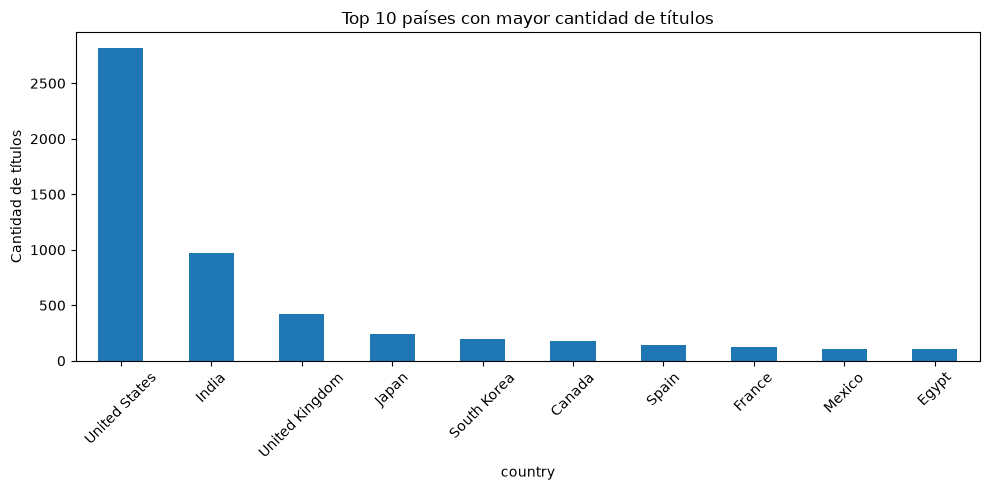

In [70]:
# tu código acá

top10 = df["country"].value_counts().head(10)

top10.plot(kind="bar", figsize=(10, 5), title="Top 10 países con mayor cantidad de títulos")
plt.ylabel("Cantidad de títulos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Ejercicio 12 - Genera un gráfico de barras mostrando la cantidad de:

- Movies
- TV Shows

(array([0, 1]), [Text(0, 0, 'Movie'), Text(1, 0, 'TV Show')])

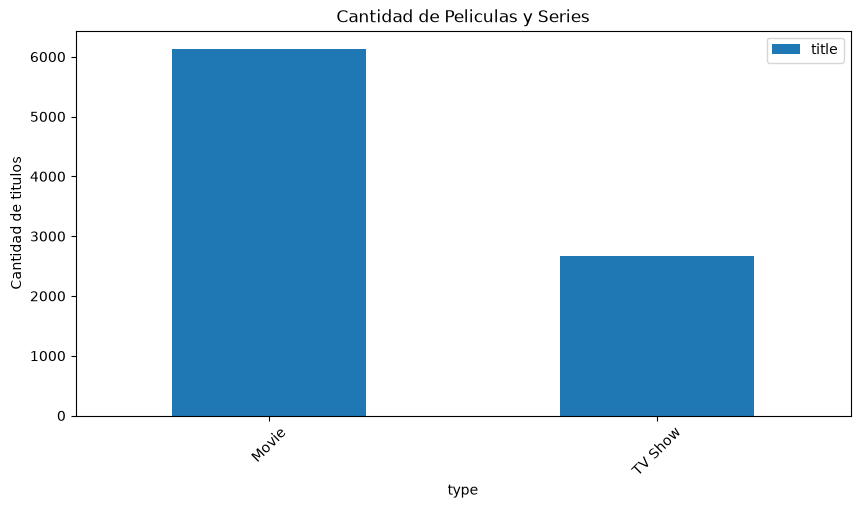

In [71]:
# tu código acá
tabla12 = df.pivot_table(
    values = "title",
    index   = "type",
    aggfunc = "count",
    fill_value= 0,

)

tabla12.plot(kind="bar", figsize=(10, 5), title="Cantidad de Peliculas y Series")
plt.ylabel("Cantidad de titulos")
plt.xticks(rotation=45)

### Ejercicio 13 - Utilizando la tabla dinámica, crea un gráfico de barras agrupadas que compare películas y series por país.


(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'United States'),
  Text(1, 0, 'India'),
  Text(2, 0, 'United Kingdom'),
  Text(3, 0, 'Japan'),
  Text(4, 0, 'South Korea'),
  Text(5, 0, 'Canada'),
  Text(6, 0, 'Spain'),
  Text(7, 0, 'France'),
  Text(8, 0, 'Mexico'),
  Text(9, 0, 'Egypt')])

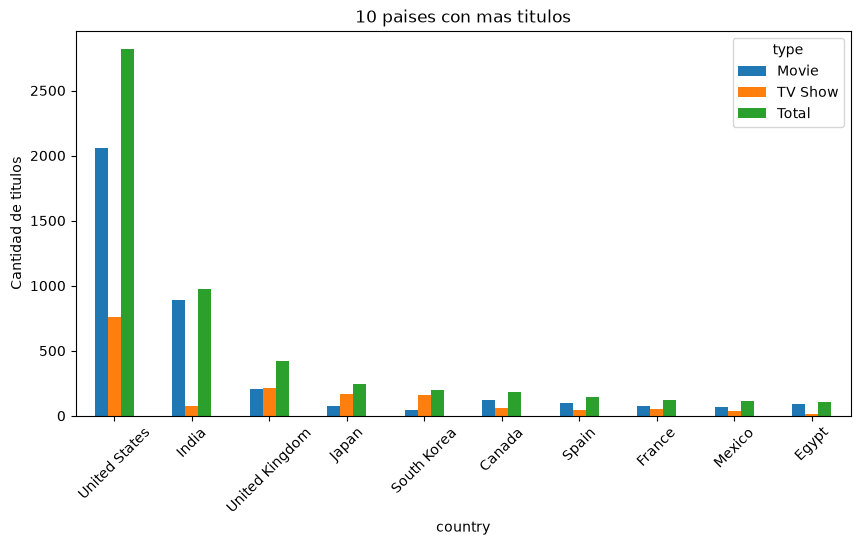

In [72]:
# tu código acá

tabla = df.pivot_table(
    values  = "title",
    index   = "country",
    columns = "type",
    aggfunc = "count",
    fill_value= 0,
)

tabla["Total"] = tabla.sum(axis=1)
tabla = tabla.sort_values("Total", ascending=False)

tabla10 = tabla.head(10)

tabla10.plot(kind="bar", figsize=(10, 5), title="10 paises con mas titulos")
plt.ylabel("Cantidad de titulos")
plt.xticks(rotation=45)

## Parte 6: Análisis

Redacta al menos **cinco insights** basados en el análisis realizado. Algunas preguntas que puedes responder son:

- ¿Qué país domina el catálogo?
- ¿Netflix posee más películas o más series?
- ¿Qué clasificación por edades es la más utilizada?
- ¿Existen países donde predominen las series?
- ¿Qué tendencia observas respecto al año de lanzamiento de los contenidos?

Justifica cada respuesta utilizando los datos obtenidos.

In [ ]:
# tu código acá
# 1) El pais que domina el catalogo es Estado Unidos con mas de 2500 titulos.
# 2) Netflix posee mas peliculas (6131) que series (2673)
# 3) La clasificacion mas usada es TV MA con 3207 titulos
# 4) Si, en Japon, Corea e Inglaterra son los paises donde mas predominan las series
# 5) Observo tendencias a lanzar mas peliculas que series en los ultimos años

## Desafío

Netflix desea aumentar su presencia en Latinoamérica. Analiza únicamente los siguientes países:

- Argentina
- Brasil
- Chile
- Colombia
- México
- Perú

Responde:

1. ¿Cuál aporta mayor cantidad de contenido?
2. ¿Predominan las películas o las series?
3. ¿Qué clasificación por edades es la más común?
4. Genera un gráfico comparativo.
5. Escribe una breve recomendación para el director regional de Netflix basada en tus resultados.


Contenido por país:
pais
Mexico       169
Brazil        97
Argentina     91
Colombia      52
Chile         29
Peru          10
Name: count, dtype: int64

Películas y series por país:
type       Movie  TV Show
pais                     
Argentina     71       20
Brazil        66       31
Chile         24        5
Colombia      20       32
Mexico       111       58
Peru          10        0

Total:
type
Movie      302
TV Show    146
dtype: int64

Clasificación más común:
rating
TV-MA    286
Name: count, dtype: int64


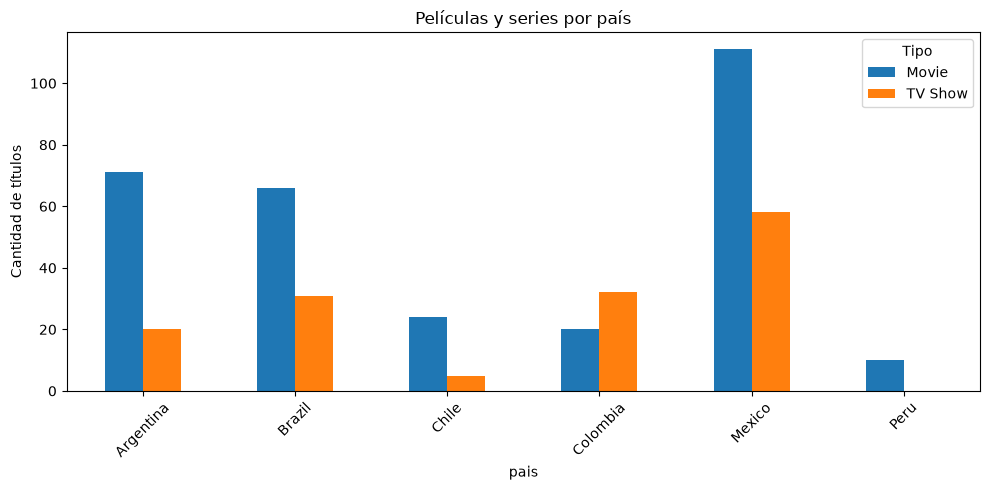

In [73]:
# tu código acá

paises = ["Argentina", "Brazil", "Chile", "Colombia", "Mexico", "Peru"]

latam = df.assign(pais=df["country"].str.split(", ")).explode("pais")
latam = latam[latam["pais"].isin(paises)]

# ¿Cuál aporta más contenido?
print("Contenido por país:")
print(latam["pais"].value_counts())

# ¿Películas o series?
tabla = latam.pivot_table(values="title", index="pais", columns="type", aggfunc="count", fill_value=0)
print("\nPelículas y series por país:")
print(tabla)
print("\nTotal:")
print(tabla.sum())

# 4¿Qué clasificación es la más común?
print("\nClasificación más común:")
print(latam["rating"].value_counts().head(1))

#  Gráfico comparativo
tabla.plot(kind="bar", figsize=(10, 5), title="Películas y series por país")
plt.ylabel("Cantidad de títulos")
plt.xticks(rotation=45)
plt.legend(title="Tipo")
plt.tight_layout()
plt.show()

México, Argentina y Brasil son los países que más contenido aporta al catálogo, predominando las peliculas. Mientras que en Colombia ,Chile y Perú ,lideran las series. Recomiendo seguir apostando por los paises que mas aportan al catalogo sin descuidar las series en Perú y Chile, que hoy son los países con menos contenido.